In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import numpy as np

# Load data

In [2]:
chromosomes = [f"chr{x}" for x in range(1, 23)]

In [3]:
metrics_basefolder = "../model_training/metrics_leave_out/"

## Load cluster metrics

In [4]:
cluster_metrics_files = [x for x in os.listdir(metrics_basefolder) if x.startswith("cluster_metrics_")]

In [5]:
cluster_metrics = []

for cluster_metrics_file in cluster_metrics_files:
    
    chrom = cluster_metrics_file.split(".")[0].split("_")[2]
    seed = cluster_metrics_file.split(".")[0].split("_")[4]
    
    cluster_metrics_path = os.path.join(metrics_basefolder, cluster_metrics_file)
    cluster_metrics_df = pd.read_csv(cluster_metrics_path, sep="\t")
    cluster_metrics_df["CHROM"] = chrom
    cluster_metrics_df["SEED"] = seed
    cluster_metrics.append(cluster_metrics_df[["CHROM", "SEED", "GROUP", "ACCURACY", "RECALL", "PRECISION"]])

cluster_metrics_df = pd.concat(cluster_metrics, ignore_index=True).reset_index(drop=True)

In [6]:
col_updated_group = []
for _, row in cluster_metrics_df.iterrows():
    if row["SEED"] == "0":
        if pd.isna(row["ACCURACY"]):
            col_updated_group.append("EMPTY")
        else:
            col_updated_group.append("FULL")
    else:
        col_updated_group.append(row["GROUP"])
cluster_metrics_df["GROUP"] = col_updated_group
cluster_metrics_df = cluster_metrics_df[cluster_metrics_df["GROUP"] != "EMPTY"].drop_duplicates()

## Load length metrics

In [7]:
length_metrics_files = [x for x in os.listdir(metrics_basefolder) if x.startswith("length_metrics_")]

In [8]:
length_metrics = []

for length_metrics_file in length_metrics_files:
    
    chrom = length_metrics_file.split(".")[0].split("_")[2]
    seed = length_metrics_file.split(".")[0].split("_")[4]
    
    length_metrics_path = os.path.join(metrics_basefolder, length_metrics_file)
    length_metrics_df = pd.read_csv(length_metrics_path, sep="\t")
    length_metrics_df["CHROM"] = chrom
    length_metrics_df["SEED"] = seed
    length_metrics_df["GROUP"] = ["TRAIN", "TEST"]
    length_metrics.append(length_metrics_df[["CHROM", "SEED", "GROUP", "R2"]])

length_metrics_df = pd.concat(length_metrics, ignore_index=True).reset_index(drop=True)

In [9]:
col_updated_group = []
for _, row in length_metrics_df.iterrows():
    if row["SEED"] == "0":
        col_updated_group.append("FULL")
    else:
        col_updated_group.append(row["GROUP"])
length_metrics_df["GROUP"] = col_updated_group

# Plotting

## cluster metrics

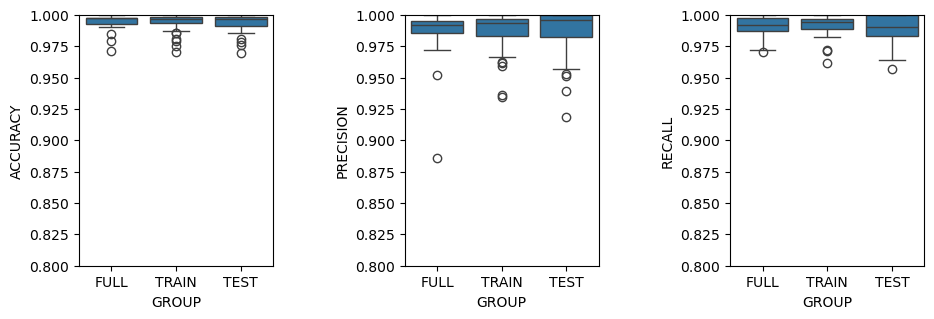

In [10]:
for i, metric in zip([1, 2, 3], ["ACCURACY", "PRECISION", "RECALL"]):
    ax = plt.subplot(1, 3, i)
    sns.boxplot(data=cluster_metrics_df, x="GROUP", y=metric, ax=ax, order=["FULL" ,"TRAIN", "TEST"])
    ax.set_ylim(0.8, 1)
plt.tight_layout()
plt.gcf().set_size_inches(10, 3)
plt.show()

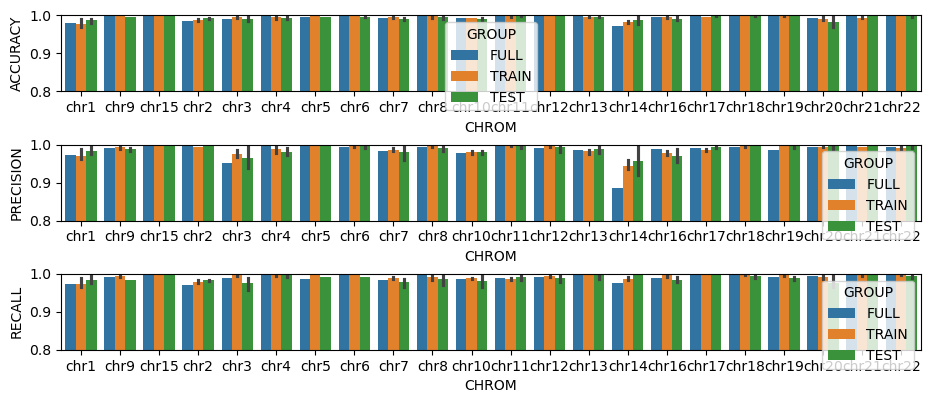

In [11]:
for i, metric in zip([1, 2, 3], ["ACCURACY", "PRECISION", "RECALL"]):
    ax = plt.subplot(3, 1, i)
    sns.barplot(
        data=cluster_metrics_df, 
        x="CHROM", 
        y=metric, 
        hue="GROUP", hue_order=["FULL", "TRAIN", "TEST"], 
        ax=ax)
    ax.set_ylim(.8, 1)
plt.tight_layout()
plt.gcf().set_size_inches(10, 4)
plt.show()

## length metrics

In [12]:
print("TRAIN: ", (length_metrics_df[length_metrics_df["GROUP"] == "TRAIN"]["R2"].mean()).round(2))
print("TEST: ", (length_metrics_df[length_metrics_df["GROUP"] == "TEST"]["R2"].mean()).round(2))
#print("Down ratio: ", (1-np.mean(ratios)).round(2))

TRAIN:  0.76
TEST:  0.74


(0.0, 1.0)

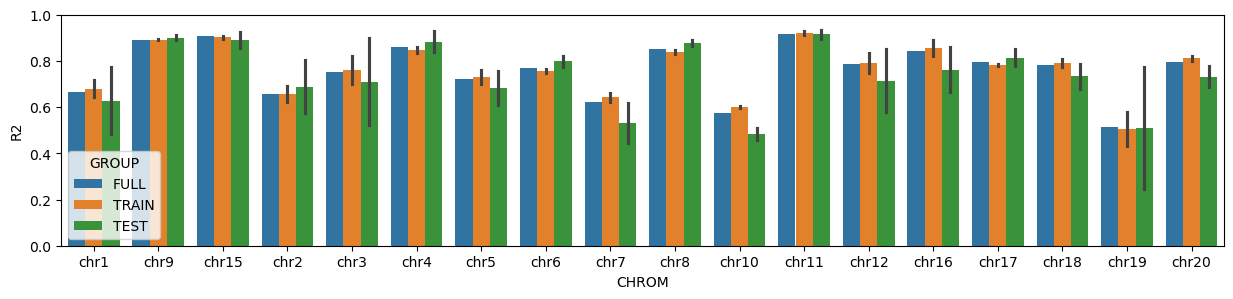

In [13]:
fig, ax = plt.subplots(figsize=(15, 3))
sns.barplot(
    data=length_metrics_df, 
    x="CHROM", y="R2", hue="GROUP", ax=ax,
    errorbar="sd", hue_order=["FULL", "TRAIN", "TEST"]
)
ax.set_ylim(0, 1)

(0.0, 1.0)

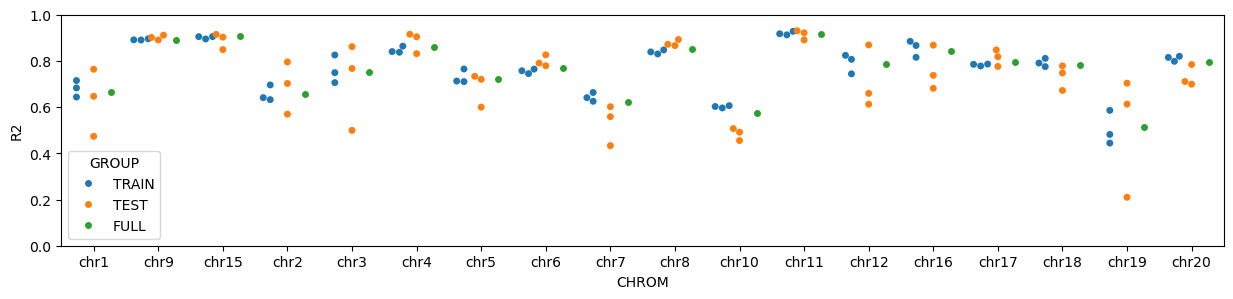

In [14]:
fig, ax = plt.subplots(figsize=(15, 3))
sns.swarmplot(
    data=length_metrics_df, 
    x="CHROM", y="R2", hue="GROUP", ax=ax,
    dodge=True
)
ax.set_ylim(0, 1)

#### Combined summary plot

In [15]:
summary_df = pd.merge(
    length_metrics_df[~pd.isna(length_metrics_df["R2"])][["CHROM", "GROUP", "SEED", "R2"]],
    cluster_metrics_df[["CHROM", "GROUP", "SEED", "ACCURACY", "RECALL", "PRECISION"]],
    on=["CHROM", "GROUP", "SEED"]
)

In [16]:
summary_df#.drop_duplicates()

,CHROM,GROUP,SEED,R2,ACCURACY,RECALL,PRECISION
0,chr1,TRAIN,10,0.715010,0.975000,0.971429,0.962264
1,chr1,TEST,10,0.473498,0.980769,0.975000,0.975000
2,chr9,TRAIN,10,0.895816,0.998355,0.994048,0.994048
3,chr9,TEST,10,0.901536,0.996556,0.983607,0.991736
4,chr15,TRAIN,10,0.905226,1.000000,1.000000,1.000000
...,...,...,...,...,...,...,...
121,chr16,FULL,0,0.841838,0.996228,0.987654,0.987654
122,chr17,FULL,0,0.797283,0.997096,0.997462,0.989924
123,chr18,FULL,0,0.780804,0.998905,1.000000,0.994595
124,chr19,FULL,0,0.516031,0.997253,0.991903,0.985915


In [ ]:
acrocentrics = ["chr12", ""]

In [17]:
summary_plot_df = pd.melt(
    summary_df,
    id_vars=["CHROM", "GROUP"],
    value_vars=["R2", "ACCURACY", "RECALL", "PRECISION"],
    var_name="Metric",
    value_name="Value"
)
summary_plot_df["Group"] = summary_plot_df \
    ["GROUP"].replace({
        "TRAIN": "Train",
        "TEST": "Test",
    })
summary_plot_df["Metric"] = summary_plot_df \
    ["Metric"].replace({
        "R2": "R2",
        "ACCURACY": "Accuracy",
        "RECALL": "Recall",
        "PRECISION": "Precision",
    })

In [18]:
for metric in ["Precision", "Recall", "Accuracy", "R2"]:
    ratios = []
    for chrom, chrom_df in summary_plot_df.groupby("CHROM"):
        ratio = chrom_df[
            (chrom_df["GROUP"] == "TEST") & 
            (chrom_df["Metric"] == metric)
            ]["Value"].values[0] / chrom_df[
                (chrom_df["GROUP"] == "TRAIN") & 
                (chrom_df["Metric"] == metric)]["Value"].values[0]
        if pd.isna(ratio):
            continue
        ratios.append(ratio)


    print(f"{metric} TRAIN: ", (summary_plot_df[(summary_plot_df["GROUP"] == "TRAIN") & (summary_plot_df["Metric"] == metric)]["Value"].mean()).round(3))
    print(f"{metric} TEST: ", (summary_plot_df[(summary_plot_df["GROUP"] == "TEST") & (summary_plot_df["Metric"] == metric)]["Value"].mean()).round(3))
    print(f"{metric} Down ratio: ", (1-np.mean(ratios)).round(3))
    print("-"*50)

Precision TRAIN:  0.99
Precision TEST:  0.989
Precision Down ratio:  -0.001
--------------------------------------------------
Recall TRAIN:  0.992
Recall TEST:  0.987
Recall Down ratio:  0.006
--------------------------------------------------
Accuracy TRAIN:  0.995
Accuracy TEST:  0.994
Accuracy Down ratio:  0.001
--------------------------------------------------
R2 TRAIN:  0.765
R2 TEST:  0.736
R2 Down ratio:  0.053
--------------------------------------------------


In [19]:
summary_plot_df.loc[(summary_plot_df["CHROM"] == "chr15") & (summary_plot_df["Metric"] == "Accuracy"), "Value"] = 0
summary_plot_df.loc[(summary_plot_df["CHROM"] == "chr15") & (summary_plot_df["Metric"] == "Recall"), "Value"] = 0
summary_plot_df.loc[(summary_plot_df["CHROM"] == "chr15") & (summary_plot_df["Metric"] == "Precision"), "Value"] = 0

In [20]:
summary_plot_df = summary_plot_df[summary_plot_df["Value"] > 0]

KeyboardInterrupt: 

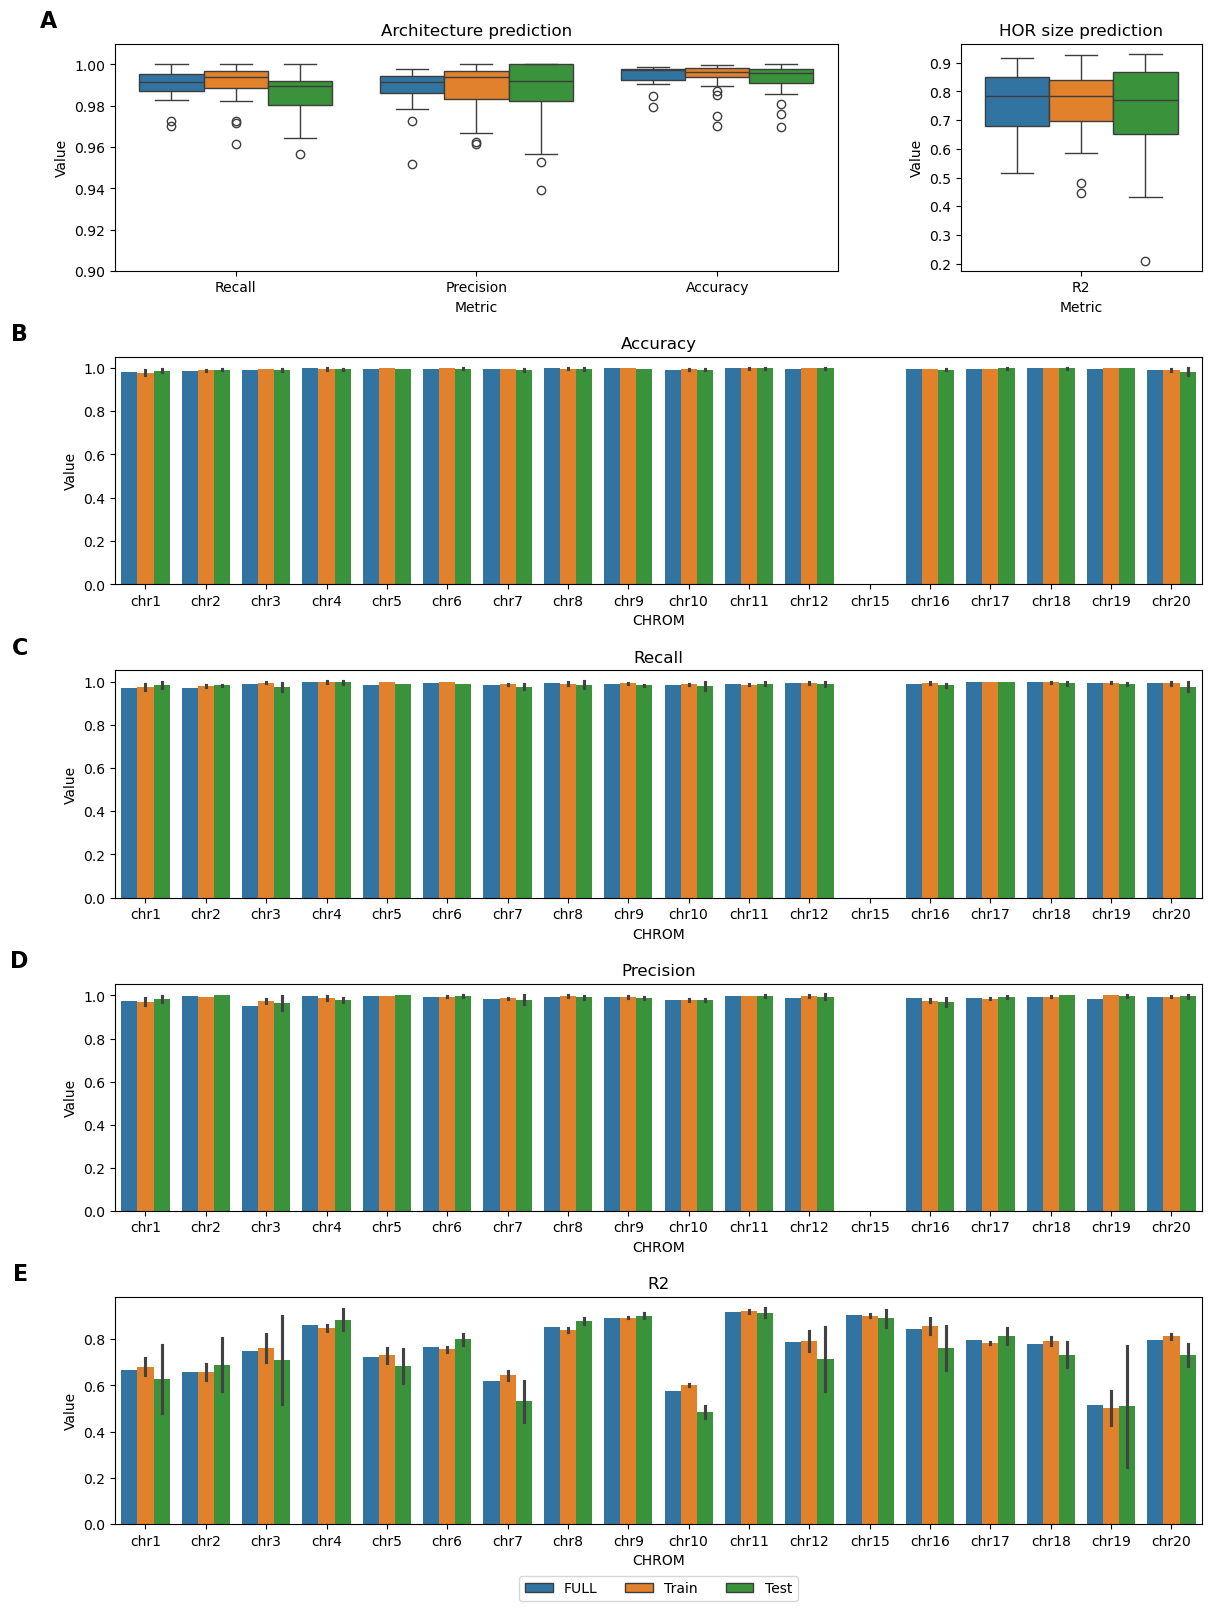

In [ ]:
fig = plt.figure(figsize=(12, 16), layout="constrained")
gs = fig.add_gridspec(6, 2, width_ratios=[3, 1], height_ratios=[1, 1, 1, 1, 1, 0.1])

ax_top_left = fig.add_subplot(gs[0, 0])
ax_top_right = fig.add_subplot(gs[0, 1])

ax_top_left.set_ylim(0.90, 1.01)

axes_lower = [
    fig.add_subplot(gs[row, :])
    for row in range(1, 5)
]
legend_ax = fig.add_subplot(gs[5, :])
legend_ax.axis("off")

sns.boxplot(
    data=summary_plot_df,
    x="Metric",
    y="Value",
    hue="Group",
    hue_order=["FULL", "Train", "Test"],
    order=["Recall", "Precision", "Accuracy"],
    ax=ax_top_left
)

sns.boxplot(
    data=summary_plot_df,
    x="Metric",
    y="Value",
    hue="Group",
    hue_order=["FULL", "Train", "Test"],
    ax=ax_top_right,
    order=["R2"]
)

ax_top_left.set_title("Architecture prediction")
ax_top_right.set_title("HOR size prediction")

for plt_idx, metric in enumerate(["Accuracy", "Recall", "Precision", "R2"]):
    sns.barplot(
        data=summary_plot_df[summary_plot_df["Metric"] == metric], 
        x="CHROM", 
        y="Value", 
        hue="Group", 
        hue_order=["FULL", "Train", "Test"],
        ax=axes_lower[plt_idx], 
        order=[x for x in chromosomes if x in length_metrics_df["CHROM"].unique()],
        errorbar="sd"
    )
    axes_lower[plt_idx].set_title(metric)

axes = [ax_top_left, *axes_lower]
handles, labels = ax_top_left.get_legend_handles_labels()
for ax in [*axes, ax_top_right]:
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()
legend_ax.legend(handles, labels, loc="center", ncol=3)

for label, ax in zip("ABCDE", axes):
    ax.text(
        -0.08, 1.05, label,
        transform=ax.transAxes,
        fontsize=16,
        fontweight="bold",
        va="bottom",
        ha="right",
    )

plt.savefig("plots/revision_horoscope_metrics.train_test.png")
plt.show()

/tmp/ipykernel_2127244/4102605464.py:33: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


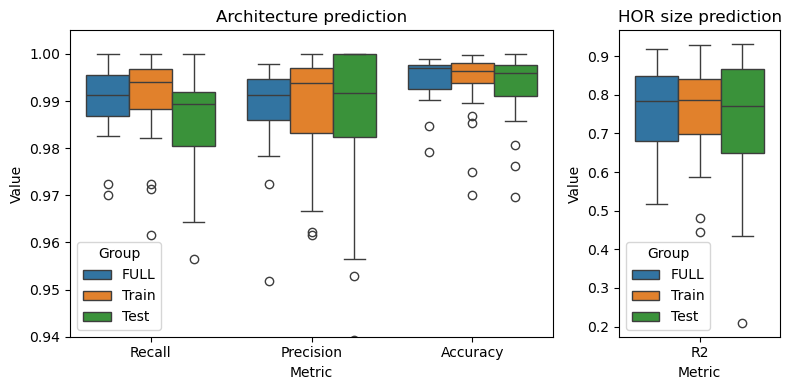

In [ ]:
fig, (ax_left, ax_right) = plt.subplots(
    1, 2,
    figsize=(8, 4),
    gridspec_kw={"width_ratios": [3, 1]},
    layout="constrained",
)

sns.boxplot(
    data=summary_plot_df,
    x="Metric",
    y="Value",
    hue="Group",
    hue_order=["FULL", "Train", "Test"],
    order=["Recall", "Precision", "Accuracy"],
    ax=ax_left
)

sns.boxplot(
    data=summary_plot_df,
    x="Metric",
    y="Value",
    hue="Group",
    hue_order=["FULL", "Train", "Test"],
    ax=ax_right,
    order=["R2"]
)

ax_left.set_title("Architecture prediction")
ax_right.set_title("HOR size prediction")

ax_left.set_ylim(0.94, 1.005)

plt.tight_layout()
plt.savefig("plots/revision_horoscope_metrics.train_test.summary.png", bbox_inches="tight")
plt.show()

In [ ]:
summary_plot_df.to_csv("horoscope_metrics_train_test.tsv", sep="\t", index=False)

In [ ]:
for group, group_df in summary_plot_df.groupby("GROUP"):
    print(f"Group: {group}")
    display(group_df.groupby("Metric").describe())    

Group: FULL


Value                                                              \
          count      mean       std       min       25%       50%       75%   
Metric                                                                        
Accuracy   17.0  0.994251  0.005359  0.979167  0.992509  0.997096  0.997577   
Precision  17.0  0.987868  0.011650  0.951807  0.985915  0.991266  0.994595   
R2         18.0  0.761398  0.115341  0.516031  0.680219  0.783946  0.849022   
Recall     17.0  0.989469  0.008237  0.970085  0.986928  0.991266  0.995423   

                     
                max  
Metric               
Accuracy   0.998905  
Precision  0.997868  
R2         0.917180  
Recall     1.000000

Group: TEST


Value                                                              \
          count      mean       std       min       25%       50%       75%   
Metric                                                                        
Accuracy   51.0  0.993731  0.006056  0.969697  0.991069  0.995902  0.997566   
Precision  51.0  0.989073  0.014287  0.939394  0.982379  0.991736  1.000000   
R2         54.0  0.736379  0.157277  0.209876  0.650138  0.771845  0.867803   
Recall     51.0  0.986464  0.011190  0.956522  0.980566  0.989474  0.991902   

                     
                max  
Metric               
Accuracy   1.000000  
Precision  1.000000  
R2         0.930615  
Recall     1.000000

Group: TRAIN


Value                                                              \
          count      mean       std       min       25%       50%       75%   
Metric                                                                        
Accuracy   51.0  0.994733  0.005707  0.970149  0.993772  0.996317  0.998034   
Precision  51.0  0.989572  0.010098  0.961538  0.983164  0.993730  0.996903   
R2         54.0  0.764785  0.112692  0.444374  0.698560  0.785889  0.840083   
Recall     51.0  0.991610  0.007826  0.961538  0.988389  0.994048  0.996755   

                     
                max  
Metric               
Accuracy   0.999665  
Precision  1.000000  
R2         0.928266  
Recall     1.000000